# TA-06: Eksplorasi Mendalam Algoritma Random Forest
**Nama:** Syifa Kanita Putri G | **NIM:** 301240016  
**Dataset:** Kelayakan Pendidikan Indonesia (dataset studi kasus TP-06)  
**Tugas:** Klasifikasi tingkat putus sekolah per provinsi (Rendah / Tinggi)

Alur notebook mengikuti ketentuan TA-06:
1. Persiapan Data & Preprocessing
2. Modeling & Eksperimen Hyperparameter (Skenario A: `n_estimators`, Skenario B: `max_depth`)
3. Analisis Feature Importance
4. Evaluasi Akhir & Kesimpulan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

os.makedirs("gambar", exist_ok=True)
RANDOM_STATE = 42
sns.set_style("whitegrid")

## 1. Persiapan Data & Preprocessing
### 1.1 Load Data

In [2]:
df = pd.read_csv("kelayakan-pendidikan-indonesia.csv")
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (39, 15)


,Provinsi,Sekolah,Siswa,Mengulang,Putus Sekolah,Kepala Sekolah dan Guru(<S1),Kepala Sekolah dan Guru(≥ S1),Tenaga Kependidikan(SM),Tenaga Kependidikan(>SM),Rombongan Belajar,Ruang kelas(baik),Ruang kelas(rusak ringan),Ruang kelas(rusak sedang),Ruang kelas(rusak berat),Unnamed: 14
0,Prov. D.K.I. Jakarta,2224,756455,1202,869,1089,38305,6967,1569,27830,23320,3886,717,345,NaN
1,Prov. Jawa Barat,19553,4487262,4778,5675,5007,209252,27487,3353,169704,59592,46006,34432,14397,NaN
2,Prov. Jawa Tengah,18618,2595050,6909,2399,2337,167535,21325,2473,127266,51050,42356,26321,13457,NaN
3,Prov. D.I. Yogyakarta,1846,270610,357,75,326,19771,4536,866,13719,8217,3878,1827,548,NaN
4,Prov. Jawa Timur,18980,2530849,4694,3327,2950,180465,21116,3818,134724,58679,42896,24218,14389,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 39 entries, 0 to 38
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Provinsi                       39 non-null     str    
 1   Sekolah                        39 non-null     int64  
 2   Siswa                          39 non-null     int64  
 3   Mengulang                      39 non-null     int64  
 4   Putus Sekolah                  39 non-null     int64  
 5   Kepala Sekolah dan Guru(<S1)   39 non-null     int64  
 6   Kepala Sekolah dan Guru(≥ S1)  39 non-null     int64  
 7   Tenaga Kependidikan(SM)        39 non-null     int64  
 8   Tenaga Kependidikan(>SM)       39 non-null     int64  
 9   Rombongan Belajar              39 non-null     int64  
 10  Ruang kelas(baik)              39 non-null     int64  
 11  Ruang kelas(rusak ringan)      39 non-null     int64  
 12  Ruang kelas(rusak sedang)      39 non-null     int64  
 13  Rua

### 1.2 Pembersihan Data
- Kolom `Unnamed: 14` kosong seluruhnya, jadi dibuang.
- Baris **Luar Negeri** bukan provinsi, jadi dibuang.
- Kolom `Provinsi` hanya identitas baris (bukan fitur), jadi tidak dipakai sebagai fitur.

In [4]:
df = df.drop(columns=["Unnamed: 14"])
df = df[df["Provinsi"] != "Luar Negeri"].reset_index(drop=True)
print("Ukuran data setelah dibersihkan:", df.shape)
print("Missing value per kolom:", df.isna().sum().sum())

Ukuran data setelah dibersihkan: (38, 14)
Missing value per kolom: 0


### 1.3 Membuat Target dan Fitur Rasio
Data berupa **jumlah mentah**, sehingga provinsi besar (mis. Jawa Barat) otomatis punya angka besar.
Agar adil, semua kolom diubah menjadi rasio:
- **Target:** `Putus Sekolah` per 1.000 siswa. Provinsi di atas median = **Tinggi**, selain itu = **Rendah**.
- **Fitur:** kolom lain dibuat per 1.000 siswa, sedangkan kondisi ruang kelas dibuat proporsi dari total ruang kelas.
- Kolom `Putus Sekolah` dan `Siswa` tidak dipakai sebagai fitur (sumber target, agar tidak terjadi kebocoran data).

In [5]:
# Target
df["putus_per_1000"] = df["Putus Sekolah"] / df["Siswa"] * 1000
median_putus = df["putus_per_1000"].median()
df["Tingkat_Putus_Sekolah"] = np.where(df["putus_per_1000"] > median_putus, "Tinggi", "Rendah")
print(f"Median putus sekolah per 1.000 siswa: {median_putus:.3f}")

# Fitur rasio per 1.000 siswa
per_siswa = {
    "Sekolah": "Sekolah_per_1000_siswa",
    "Mengulang": "Mengulang_per_1000_siswa",
    "Kepala Sekolah dan Guru(<S1)": "Guru_kurang_S1_per_1000_siswa",
    "Kepala Sekolah dan Guru(≥ S1)": "Guru_S1_ke_atas_per_1000_siswa",
    "Tenaga Kependidikan(SM)": "Tendik_SM_per_1000_siswa",
    "Tenaga Kependidikan(>SM)": "Tendik_di_atas_SM_per_1000_siswa",
    "Rombongan Belajar": "Rombel_per_1000_siswa",
}
fitur = pd.DataFrame({new: df[old] / df["Siswa"] * 1000 for old, new in per_siswa.items()})

# Fitur proporsi kondisi ruang kelas
kelas_cols = {
    "Ruang kelas(baik)": "Prop_kelas_baik",
    "Ruang kelas(rusak ringan)": "Prop_kelas_rusak_ringan",
    "Ruang kelas(rusak sedang)": "Prop_kelas_rusak_sedang",
    "Ruang kelas(rusak berat)": "Prop_kelas_rusak_berat",
}
total_kelas = df[list(kelas_cols)].sum(axis=1)
for old, new in kelas_cols.items():
    fitur[new] = df[old] / total_kelas

print("Jumlah fitur:", fitur.shape[1])
fitur.head()

Median putus sekolah per 1.000 siswa: 2.253
Jumlah fitur: 11


,Sekolah_per_1000_siswa,Mengulang_per_1000_siswa,Guru_kurang_S1_per_1000_siswa,Guru_S1_ke_atas_per_1000_siswa,Tendik_SM_per_1000_siswa,Tendik_di_atas_SM_per_1000_siswa,Rombel_per_1000_siswa,Prop_kelas_baik,Prop_kelas_rusak_ringan,Prop_kelas_rusak_sedang,Prop_kelas_rusak_berat
0,2.940029,1.588991,1.439610,50.637513,9.210065,2.074148,36.790027,0.824961,0.137470,0.025364,0.012205
1,4.357446,1.064792,1.115825,46.632445,6.125562,0.747226,37.819053,0.385891,0.297914,0.222966,0.093229
2,7.174428,2.662376,0.900561,64.559450,8.217568,0.952968,49.041830,0.383304,0.318026,0.197629,0.101041
3,6.821625,1.319242,1.204686,73.060862,16.762130,3.200177,50.696574,0.567865,0.268003,0.126261,0.037871
4,7.499460,1.854714,1.165617,71.306111,8.343445,1.508585,53.232729,0.418592,0.306002,0.172761,0.102645


### 1.4 Encoding
Seluruh fitur sudah numerik, sehingga satu-satunya data kategori yang perlu di-encode adalah **label target** (Label Encoding):
Rendah = 0, Tinggi = 1.

In [6]:
le = LabelEncoder()
y = le.fit_transform(df["Tingkat_Putus_Sekolah"])
X = fitur.copy()
print("Pemetaan label:", dict(zip(le.classes_, le.transform(le.classes_))))

Pemetaan label: {'Rendah': np.int64(0), 'Tinggi': np.int64(1)}


### 1.5 Analisis Awal: Cek Ketidakseimbangan Kelas (Imbalance)

Tingkat_Putus_Sekolah
Rendah    19
Tinggi    19
Name: count, dtype: int64

Persentase:
 Tingkat_Putus_Sekolah
Rendah    50.0
Tinggi    50.0
Name: count, dtype: float64


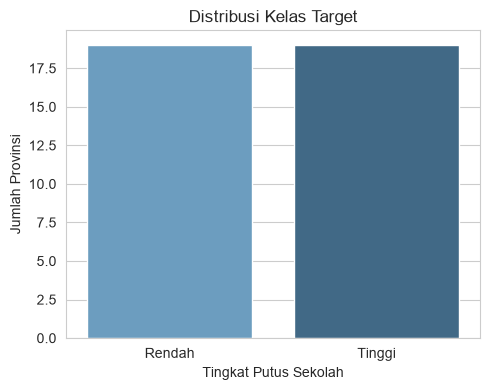

In [7]:
dist = df["Tingkat_Putus_Sekolah"].value_counts()
print(dist)
print("\nPersentase:\n", (dist / dist.sum() * 100).round(1))

plt.figure(figsize=(5, 4))
sns.barplot(x=dist.index, y=dist.values, palette="Blues_d", hue=dist.index, legend=False)
plt.title("Distribusi Kelas Target")
plt.xlabel("Tingkat Putus Sekolah"); plt.ylabel("Jumlah Provinsi")
plt.tight_layout(); plt.savefig("gambar/01_distribusi_kelas.png", dpi=150); plt.show()

### 1.6 Split Data: Training 80% dan Testing 20%
`stratify=y` dipakai agar proporsi kelas di training dan testing tetap sama.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Training:", X_train.shape, "| Testing:", X_test.shape)
print("Distribusi y_test:", np.bincount(y_test))

Training: (30, 11) | Testing: (8, 11)
Distribusi y_test: [4 4]


## 2. Modeling & Eksperimen Hyperparameter
### Skenario A: Pengaruh Jumlah Pohon (`n_estimators`)
Nilai yang diuji: **[10, 50, 100, 200, 500]**.

In [9]:
n_list = [10, 50, 100, 200, 500]
hasil_a = []
for n in n_list:
    rf = RandomForestClassifier(n_estimators=n, random_state=RANDOM_STATE)
    rf.fit(X_train, y_train)
    hasil_a.append({
        "n_estimators": n,
        "Akurasi Training": accuracy_score(y_train, rf.predict(X_train)),
        "Akurasi Testing": accuracy_score(y_test, rf.predict(X_test)),
    })
df_a = pd.DataFrame(hasil_a)
df_a

,n_estimators,Akurasi Training,Akurasi Testing
0,10,1.0,0.625
1,50,1.0,0.625
2,100,1.0,0.625
3,200,1.0,0.625
4,500,1.0,0.625


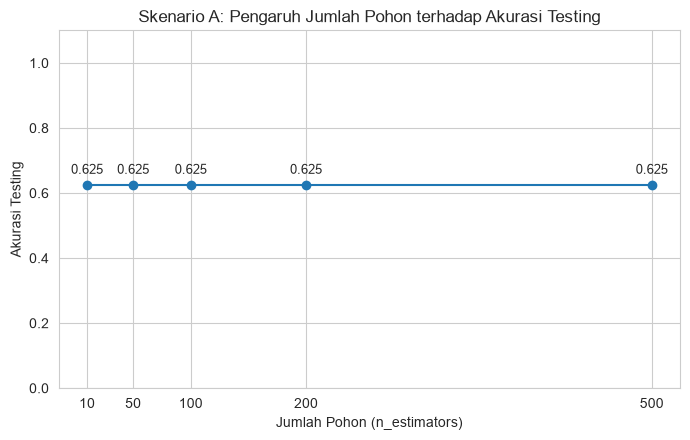

In [10]:
plt.figure(figsize=(7, 4.5))
plt.plot(df_a["n_estimators"], df_a["Akurasi Testing"], marker="o", color="tab:blue")
for _, r in df_a.iterrows():
    plt.annotate(f"{r['Akurasi Testing']:.3f}", (r["n_estimators"], r["Akurasi Testing"]),
                 textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
plt.xlabel("Jumlah Pohon (n_estimators)"); plt.ylabel("Akurasi Testing")
plt.title("Skenario A: Pengaruh Jumlah Pohon terhadap Akurasi Testing")
plt.ylim(0, 1.1); plt.xticks(n_list)
plt.tight_layout(); plt.savefig("gambar/02_skenario_a.png", dpi=150); plt.show()

In [11]:
# Pilih n_estimators terbaik: akurasi testing tertinggi; jika seri, pilih yang paling kecil (paling efisien)
best_a = df_a.sort_values(["Akurasi Testing", "n_estimators"], ascending=[False, True]).iloc[0]
best_n = int(best_a["n_estimators"])
print(f"n_estimators terbaik dari Skenario A: {best_n} (akurasi testing = {best_a['Akurasi Testing']:.3f})")

n_estimators terbaik dari Skenario A: 10 (akurasi testing = 0.625)


**Analisis Skenario A:** Akurasi testing bernilai **0,625 untuk semua jumlah pohon** (10 sampai 500), sedangkan akurasi training selalu 1,0. Jadi menambah pohon terus-menerus **tidak meningkatkan akurasi secara signifikan**. Ada dua penyebabnya: (1) data testing hanya 8 baris sehingga satu prediksi saja mengubah akurasi sebesar 12,5%, dan perubahan kecil tidak terlihat; (2) dengan data sekecil ini, 10 pohon sudah cukup untuk hasil yang stabil. Menambah pohon hanya menambah waktu komputasi dan memori (sesuai kelemahan Random Forest di modul). Karena hasilnya seri, dipilih nilai paling kecil dan paling efisien: **n_estimators = 10**.

### Skenario B: Pengaruh Kedalaman Pohon (`max_depth`)
Memakai `n_estimators` terbaik dari Skenario A. Nilai yang diuji: **[None (Unlimited), 3, 5, 10, 20]**.

In [12]:
depth_list = [None, 3, 5, 10, 20]
hasil_b = []
for d in depth_list:
    rf = RandomForestClassifier(n_estimators=best_n, max_depth=d, random_state=RANDOM_STATE)
    rf.fit(X_train, y_train)
    tr = accuracy_score(y_train, rf.predict(X_train))
    te = accuracy_score(y_test, rf.predict(X_test))
    hasil_b.append({"max_depth": "None" if d is None else d,
                    "Akurasi Training": tr, "Akurasi Testing": te, "Selisih (Train-Test)": tr - te})
df_b = pd.DataFrame(hasil_b)
df_b

,max_depth,Akurasi Training,Akurasi Testing,Selisih (Train-Test)
0,None,1.0,0.625,0.375
1,3,1.0,0.625,0.375
2,5,1.0,0.625,0.375
3,10,1.0,0.625,0.375
4,20,1.0,0.625,0.375


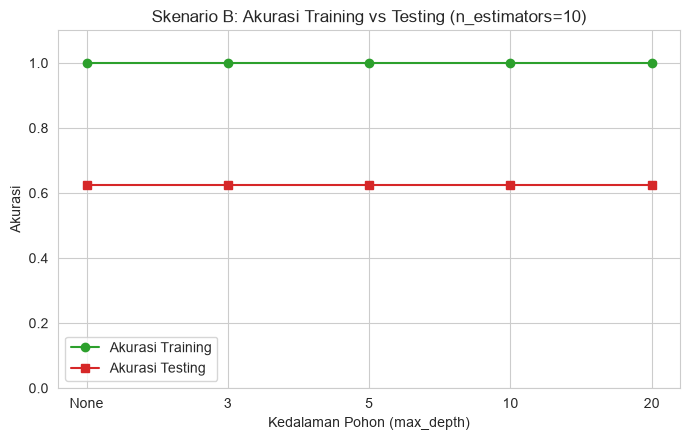

In [13]:
labels = df_b["max_depth"].astype(str).tolist()
plt.figure(figsize=(7, 4.5))
plt.plot(labels, df_b["Akurasi Training"], marker="o", label="Akurasi Training", color="tab:green")
plt.plot(labels, df_b["Akurasi Testing"], marker="s", label="Akurasi Testing", color="tab:red")
plt.xlabel("Kedalaman Pohon (max_depth)"); plt.ylabel("Akurasi")
plt.title(f"Skenario B: Akurasi Training vs Testing (n_estimators={best_n})")
plt.ylim(0, 1.1); plt.legend()
plt.tight_layout(); plt.savefig("gambar/03_skenario_b.png", dpi=150); plt.show()

In [14]:
# Pilih max_depth terbaik: akurasi testing tertinggi; jika seri, pilih selisih train-test terkecil (paling stabil),
# lalu kedalaman yang lebih dangkal (model lebih sederhana)
df_b["_urut"] = [10**6 if d == "None" else d for d in df_b["max_depth"]]
best_b = df_b.sort_values(["Akurasi Testing", "Selisih (Train-Test)", "_urut"],
                          ascending=[False, True, True]).iloc[0]
best_depth = None if best_b["max_depth"] == "None" else int(best_b["max_depth"])
print(f"max_depth terbaik dari Skenario B: {best_b['max_depth']} "
      f"(testing = {best_b['Akurasi Testing']:.3f}, selisih = {best_b['Selisih (Train-Test)']:.3f})")

max_depth terbaik dari Skenario B: 3 (testing = 0.625, selisih = 0.375)


**Analisis Skenario B:** Akurasi training = 1,0 dan akurasi testing = 0,625 pada **semua** kedalaman (None, 3, 5, 10, 20), dengan selisih 0,375. Artinya tanda *overfitting* (training tinggi, testing rendah) sudah muncul sejak **max_depth = 3**, yaitu kedalaman paling dangkal yang diuji, dan membatasi kedalaman tidak mengurangi selisihnya. Penyebabnya, dengan hanya 30 data latih, pohon sedangkal apa pun sudah mampu menghafal data training. Karena hasilnya seri, dipilih model paling sederhana dengan selisih paling kecil: **max_depth = 3**. Catatan: ini lebih mencerminkan keterbatasan ukuran data (38 provinsi) daripada kelemahan algoritma.

## 3. Analisis Feature Importance
Memakai model terbaik dari kedua eksperimen di atas.

In [15]:
model_terbaik = RandomForestClassifier(n_estimators=best_n, max_depth=best_depth, random_state=RANDOM_STATE)
model_terbaik.fit(X_train, y_train)

imp = pd.DataFrame({"Fitur": X.columns, "Importance": model_terbaik.feature_importances_})
imp = imp.sort_values("Importance", ascending=False).reset_index(drop=True)
top10 = imp.head(10)
top10

,Fitur,Importance
0,Prop_kelas_baik,0.191666
1,Guru_kurang_S1_per_1000_siswa,0.133753
2,Mengulang_per_1000_siswa,0.126136
3,Prop_kelas_rusak_sedang,0.123493
4,Prop_kelas_rusak_berat,0.103530
5,Guru_S1_ke_atas_per_1000_siswa,0.082108
6,Rombel_per_1000_siswa,0.064650
7,Sekolah_per_1000_siswa,0.062029
8,Tendik_di_atas_SM_per_1000_siswa,0.044708
9,Tendik_SM_per_1000_siswa,0.036658


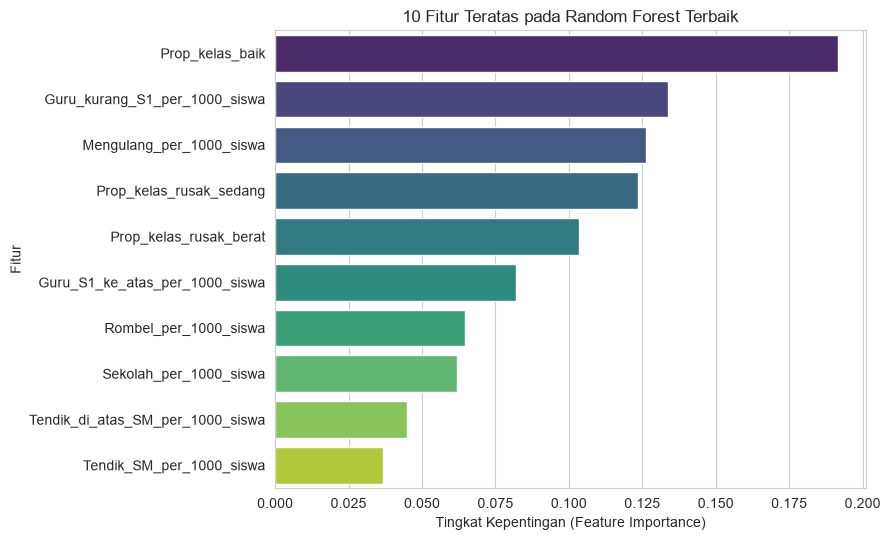

In [16]:
plt.figure(figsize=(9, 5.5))
sns.barplot(x=top10["Importance"], y=top10["Fitur"], palette="viridis", hue=top10["Fitur"], legend=False)
plt.xlabel("Tingkat Kepentingan (Feature Importance)"); plt.ylabel("Fitur")
plt.title("10 Fitur Teratas pada Random Forest Terbaik")
plt.tight_layout(); plt.savefig("gambar/04_feature_importance.png", dpi=150); plt.show()

**Interpretasi:** Lima fitur teratas adalah **proporsi ruang kelas baik** (0,19), **guru berkualifikasi di bawah S1** (0,13), **angka mengulang kelas** (0,13), serta **proporsi ruang kelas rusak sedang** (0,12) dan **rusak berat** (0,10). Pola ini masuk akal secara teori pendidikan: kondisi sarana belajar yang buruk, kualifikasi guru yang rendah, dan banyaknya siswa mengulang kelas umumnya berkaitan dengan risiko putus sekolah yang lebih tinggi. Dua catatan kehati-hatian: (1) ini hubungan (korelasi), bukan bukti sebab-akibat; (2) selisih skor antarfitur teratas kecil dan datanya hanya 38 baris, sehingga peringkat bisa berubah bila data berubah.

## 4. Evaluasi Akhir & Kesimpulan
### 4.1 Classification Report Model Terbaik

In [17]:
y_pred = model_terbaik.predict(X_test)
print(f"Konfigurasi terbaik: n_estimators={best_n}, max_depth={best_depth}")
print("Akurasi Testing:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n",
      classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))

Konfigurasi terbaik: n_estimators=10, max_depth=3
Akurasi Testing: 0.625

Classification Report:
               precision    recall  f1-score   support

      Rendah       0.60      0.75      0.67         4
      Tinggi       0.67      0.50      0.57         4

    accuracy                           0.62         8
   macro avg       0.63      0.62      0.62         8
weighted avg       0.63      0.62      0.62         8



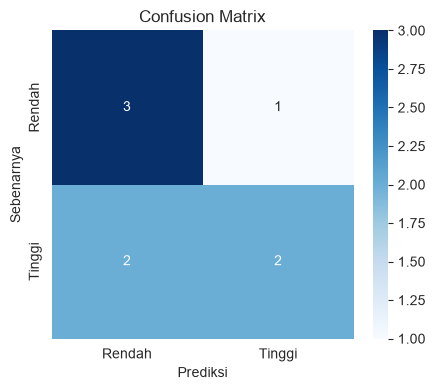

In [18]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Prediksi"); plt.ylabel("Sebenarnya"); plt.title("Confusion Matrix")
plt.tight_layout(); plt.savefig("gambar/05_confusion_matrix.png", dpi=150); plt.show()

In [19]:
# Ringkasan otomatis untuk bahan kesimpulan
print("=== Skenario A ===");  print(df_a.round(3).to_string(index=False))
print("\n=== Skenario B ===");  print(df_b.drop(columns='_urut').round(3).to_string(index=False))
print("\nTop 3 fitur:", ", ".join(top10['Fitur'].head(3)))

=== Skenario A ===
 n_estimators  Akurasi Training  Akurasi Testing
           10               1.0            0.625
           50               1.0            0.625
          100               1.0            0.625
          200               1.0            0.625
          500               1.0            0.625

=== Skenario B ===
max_depth  Akurasi Training  Akurasi Testing  Selisih (Train-Test)
     None               1.0            0.625                 0.375
        3               1.0            0.625                 0.375
        5               1.0            0.625                 0.375
       10               1.0            0.625                 0.375
       20               1.0            0.625                 0.375

Top 3 fitur: Prop_kelas_baik, Guru_kurang_S1_per_1000_siswa, Mengulang_per_1000_siswa


### 4.2 Kesimpulan
- **Konfigurasi terpilih:** `n_estimators = 10` dan `max_depth = 3`. Semua konfigurasi menghasilkan akurasi testing sama (62,5%), sehingga dipilih yang paling sederhana dan efisien.
- **Kinerja:** akurasi testing 62,5% (5 dari 8 provinsi benar). F1-score kelas Rendah 0,67 dan kelas Tinggi 0,57.
- **Stabilitas:** model **belum dapat dikatakan stabil**. Akurasi training 100% berbanding testing 62,5% menunjukkan overfitting yang muncul di semua kedalaman, dan hasilnya tidak berubah saat jumlah pohon ditambah. Penyebab utamanya adalah data yang sangat kecil (38 baris, testing 8 baris), bukan pemilihan hyperparameter.
- **Wawasan bisnis (business insight):** fitur yang paling berpengaruh berkaitan dengan kondisi ruang kelas, kualifikasi guru, dan angka mengulang kelas. Provinsi dengan ruang kelas banyak rusak, guru berkualifikasi rendah, dan angka mengulang tinggi layak diprioritaskan untuk intervensi (perbaikan sarana, peningkatan kualifikasi guru, dan program pencegahan putus sekolah).
- **Saran pengembangan:** menambah data (misalnya data per kabupaten/kota) akan membuat eksperimen hyperparameter jauh lebih informatif.

In [20]:
import joblib
joblib.dump({
    "model": model_terbaik,
    "fitur": list(X.columns),
    "min": X.min().to_dict(),
    "max": X.max().to_dict(),
    "median": X.median().to_dict(),
    "kelas": list(le.classes_),
}, "model_rf.joblib")
print("Model tersimpan")

Model tersimpan
